# 05 Coefficients and feature importances for each model type (all models together)

Shared step of `03b_training_pipeline_model`: the retrained models saved by each folder's `03_retrain.ipynb` are loaded (nothing is retrained) and opened up:

- **Two-stage models, stage 1 (trend):** the coefficients of the Lasso or Ridge on the standardised temporal features (stock and economy). One value
  is the change in the trend (log rent) for a one-standard-deviation rise in the feature. A Lasso drops features (coefficient exactly zero); a Ridge
  keeps all of them and only shrinks.
- **Two-stage models, stage 2 (static model):** the random forest's impurity importances, as a share of the total, for the static features (and the
  interaction features when that setup uses them). Impurity importances favour features with many distinct values and say nothing about direction.
- **Single-stage models:** the coefficients on the standardised columns (static features, temporal features and interactions). A Lasso zeroes
  features out; a Ridge shares weight across correlated columns, so read single coefficients with care.

None of these are causal effects.

In [1]:
import importlib.util
import json
import os
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SHARED_DIR = '/Users/keltonn/Desktop/Projects/housing_price_regressor/03b_training_pipeline_model'
sys.path.insert(0, SHARED_DIR)
import pipeline_utils as pu
import plotting

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 100)
OUT_DIR = f'{SHARED_DIR}/outputs'
os.makedirs(OUT_DIR, exist_ok=True)
TWO_STAGE, SINGLE_STAGE = ('two_stage_rf', 'two_stage_rf_ridge'), ('single_stage_lasso', 'single_stage_ridge')
FAMILY_LABEL = {family: label for family, (label, _) in plotting.FAMILY_STYLE.items()}
meta = json.load(open(f'{pu.STATIC_DIR}/preprocessing_metadata.json'))
numeric, onehot, categorical = meta['numeric_features'], meta['encoded_columns'], meta['categorical_features']

## 1. Load the retrained models

In [2]:
def load_py(path):
    """Import a config file by path (every model folder has its own feature_config.py / model_config.py)."""
    spec = importlib.util.spec_from_file_location(os.path.basename(path)[:-3], path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


WINDOWS = list(pu.WINDOW_START)
FAMILIES = list(pu.FAMILIES)
KEYS_ORDER = [f'{w}/{f}' for w in WINDOWS for f in FAMILIES]                     # window-major, as in the 03_training_pipeline outputs
setups = {}
fitted = {}
for family in FAMILIES:
    setups.update(load_py(f'{SHARED_DIR}/{family}/model_config.py').BEST_SETUPS)
    for window in WINDOWS:
        fitted[f'{window}/{family}'] = joblib.load(f'{SHARED_DIR}/{family}/outputs/{window}.joblib')
fitted = {key: fitted[key] for key in KEYS_ORDER}
print(len(fitted), 'retrained models loaded from the model folders:', ', '.join(fitted))


def group_of(name):
    """Static numeric features stay individual; one-hot columns are grouped by their original categorical feature."""
    if ' x ' in name:
        return 'interaction features'
    for c in categorical:
        if name.startswith(c + '_'):
            return f'{c} (categorical)'
    return name


def grid(families, height, title, path, draw):
    """One panel per (family, window): families down the rows, windows across the columns."""
    fig, axes = plt.subplots(len(families), len(WINDOWS), figsize=(8.5 * len(WINDOWS), height), facecolor=plotting.SURFACE, squeeze=False)
    for r, family in enumerate(families):
        for c, window in enumerate(WINDOWS):
            draw(axes[r][c], f'{window}/{family}', f'{FAMILY_LABEL[family]}, {window.replace("_", " ")}')
    fig.suptitle(title, x=0.02, ha='left', fontsize=13, fontweight='semibold')
    fig.tight_layout(rect=(0, 0, 1, 0.96)); fig.savefig(path, dpi=160, facecolor=plotting.SURFACE); plt.show()

12 retrained models loaded from the model folders: full_history/two_stage_rf, full_history/two_stage_rf_ridge, full_history/single_stage_lasso, full_history/single_stage_ridge, from_2023/two_stage_rf, from_2023/two_stage_rf_ridge, from_2023/single_stage_lasso, from_2023/single_stage_ridge, from_2023_06/two_stage_rf, from_2023_06/two_stage_rf_ridge, from_2023_06/single_stage_lasso, from_2023_06/single_stage_ridge


## 2. Two-stage models, stage 1: trend coefficients (Lasso vs Ridge)

Fit on the selected stock and economy features (standardised on the fitting months). For the Lasso, zero means the feature was dropped; the Ridge keeps
every selected feature with a shrunken coefficient.

full_history/two_stage_rf: penalty 0.0001, intercept 7.8770, 8 of 9 features with a nonzero coefficient
full_history/two_stage_rf_ridge: penalty 0.01, intercept 7.8770, 9 of 9 features with a nonzero coefficient
from_2023/two_stage_rf: penalty 0.01, intercept 8.0030, 3 of 10 features with a nonzero coefficient
from_2023/two_stage_rf_ridge: penalty 10, intercept 8.0030, 10 of 10 features with a nonzero coefficient
from_2023_06/two_stage_rf: penalty 0.0001, intercept 8.0122, 9 of 10 features with a nonzero coefficient
from_2023_06/two_stage_rf_ridge: penalty 0.01, intercept 8.0122, 10 of 10 features with a nonzero coefficient


,kind,full_history/two_stage_rf,full_history/two_stage_rf_ridge,from_2023/two_stage_rf,from_2023/two_stage_rf_ridge,from_2023_06/two_stage_rf,from_2023_06/two_stage_rf_ridge
MACRO_PRIVATE_RENT_RPI_YOY,economy,-0.0023,-0.0018,,,,
MACRO_SORA_3M_PCT,economy,0.0655,0.0683,-0.0,-0.0002,,
coe_c_log_quota_premium,COE,0.0448,0.0445,,,,
stk_cmon_return_volatility,stock,,,,,0.0023,0.0027
stk_comfortdelgro_mom_return,stock,,,0.0,0.0005,,
stk_cytomed_therapeutics_mom_return,stock,,,,,0.0017,0.0024
stk_cytomed_therapeutics_return_volatility,stock,,,,,0.0015,0.0018
stk_dbs_group_return_volatility,stock,,,,,0.0011,0.0014
stk_genius_group_return_volatility,stock,,,-0.0,-0.0022,,
stk_genting_singapore_log_price_mean,stock,-0.0256,-0.0265,,,,


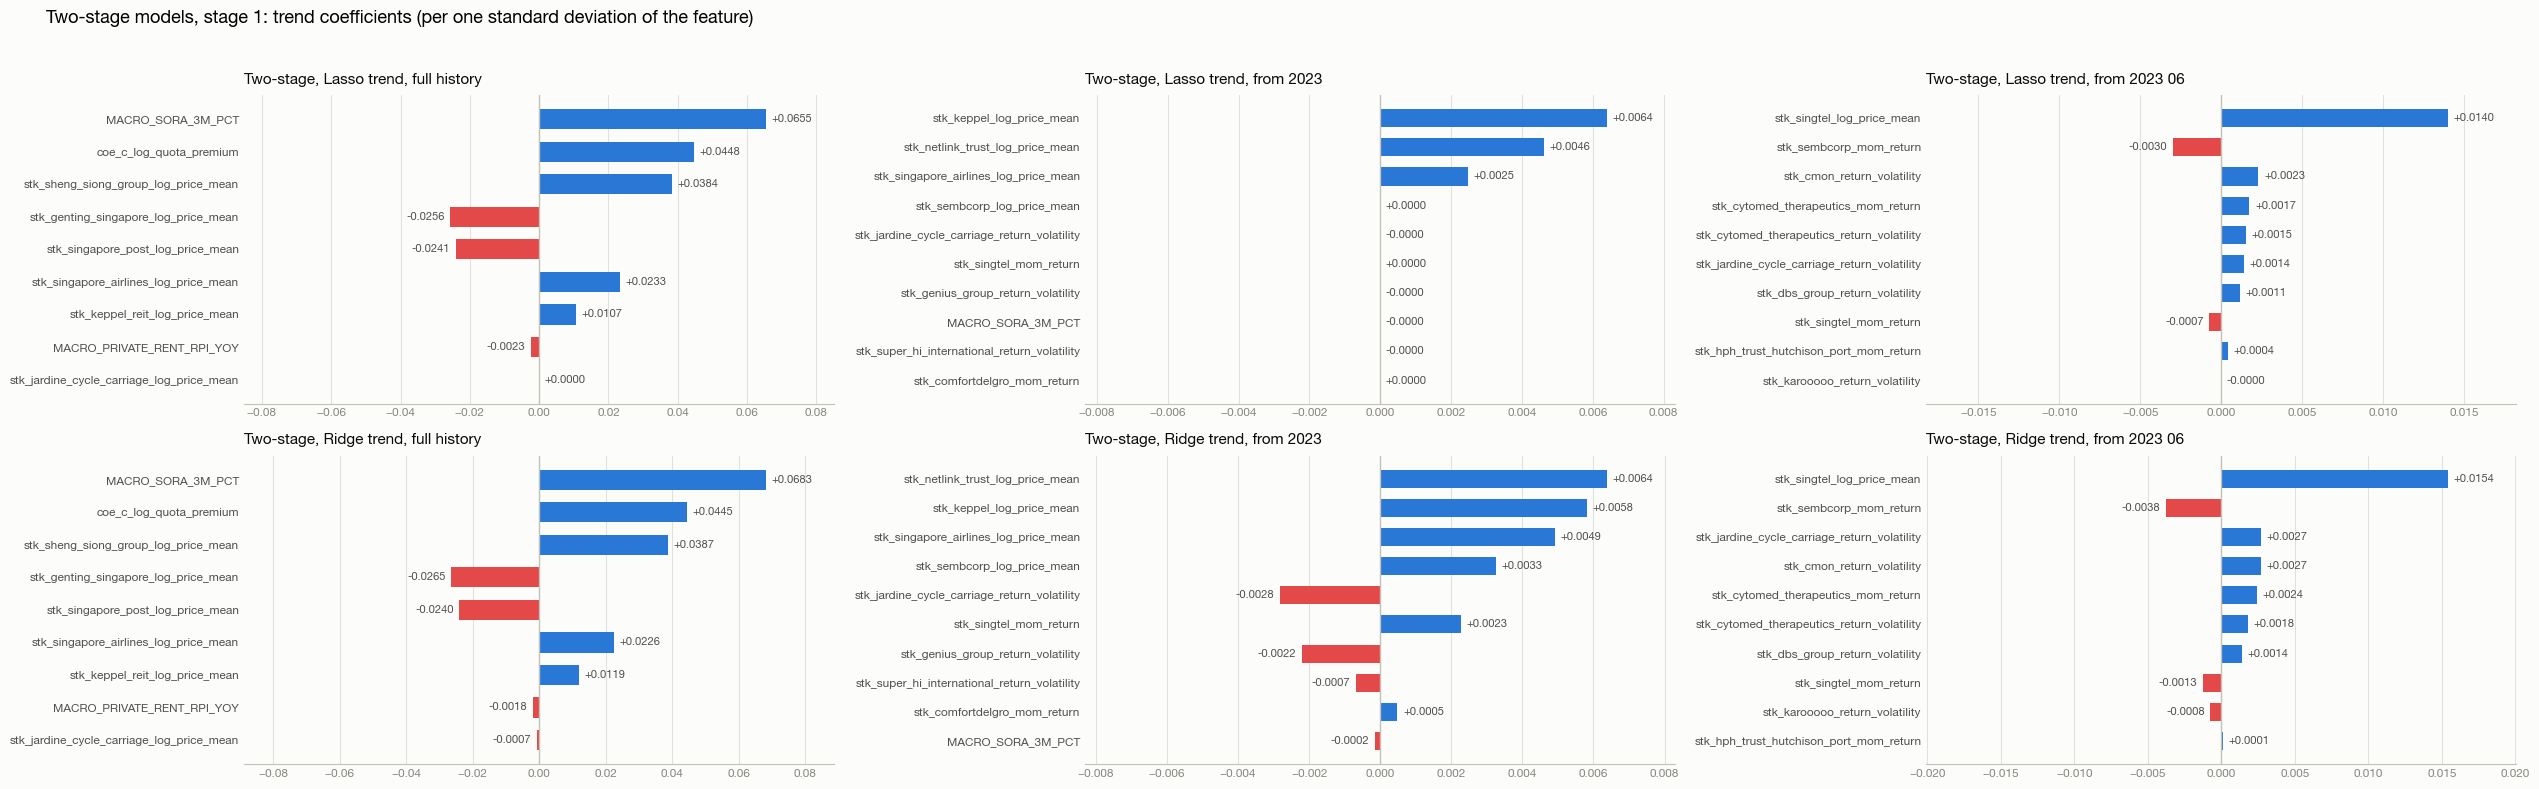

In [3]:
stage1 = {key: pd.Series(f['linear'].coef_, index=f['selected']) for key, f in fitted.items() if f['family'] in TWO_STAGE}
for key, coefs in stage1.items():
    f = fitted[key]
    penalty = f['setup'].get('lasso_alpha', f['setup'].get('ridge_alpha'))
    print(f'{key}: penalty {penalty:g}, intercept {f["linear"].intercept_:.4f}, {int((coefs.abs() > 1e-9).sum())} of {len(coefs)} features with a nonzero coefficient')
table = pd.DataFrame(stage1)
table.insert(0, 'kind', ['economy' if n.startswith('MACRO_') else 'COE' if n.startswith('coe_') else 'annual' if n.startswith('ANNUAL_') else 'stock' for n in table.index])
display(table.round(4).fillna(''))

grid(TWO_STAGE, 8, 'Two-stage models, stage 1: trend coefficients (per one standard deviation of the feature)', f'{OUT_DIR}/stage1_trend_coefficients.png',
     lambda ax, key, title: plotting.bar_panel(ax, stage1[key], title, signed=True, top=len(stage1[key]), fmt='{:+.4f}'))

## 3. Two-stage models, stage 2: random forest importances

Share of total impurity importance, grouped by original feature (categorical one-hot columns are summed; interaction features are one group). The forests
are tuned separately for the Lasso-trend and Ridge-trend families, so their settings, and therefore importances, can differ a little.

full_history/two_stage_rf: interactions used = False, 237 columns, forest depth 24
full_history/two_stage_rf_ridge: interactions used = False, 237 columns, forest depth 24
from_2023/two_stage_rf: interactions used = False, 237 columns, forest depth 14
from_2023/two_stage_rf_ridge: interactions used = False, 237 columns, forest depth 14
from_2023_06/two_stage_rf: interactions used = False, 237 columns, forest depth None
from_2023_06/two_stage_rf_ridge: interactions used = False, 237 columns, forest depth None


,full_history/two_stage_rf,full_history/two_stage_rf_ridge,from_2023/two_stage_rf,from_2023/two_stage_rf_ridge,from_2023_06/two_stage_rf,from_2023_06/two_stage_rf_ridge
"top groups, share of importance",,,,,,
FLAT_MODEL (categorical),0.0215,0.0215,0.0232,0.0232,0.0255,0.0255
FLAT_TYPE (categorical),0.1757,0.1757,0.1909,0.1909,0.2437,0.2437
FLOOR_AREA_SQM,0.328,0.328,0.366,0.366,0.3182,0.3182
MAX_FLOOR (categorical),0.0246,0.0246,0.0225,0.0225,0.0186,0.0186
nearest_jc_school_m,0.038,0.038,0.0293,0.0293,0.0268,0.0268
nearest_pri_school_m,0.0341,0.0341,0.0262,0.0262,0.0241,0.0241
nearest_school_m,0.0329,0.0329,0.0254,0.0254,0.0237,0.0237
nearest_sec_school_m,0.0348,0.0348,0.0269,0.0269,0.0245,0.0245
nearest_station_m,0.0495,0.0495,0.0406,0.0406,0.0368,0.0368


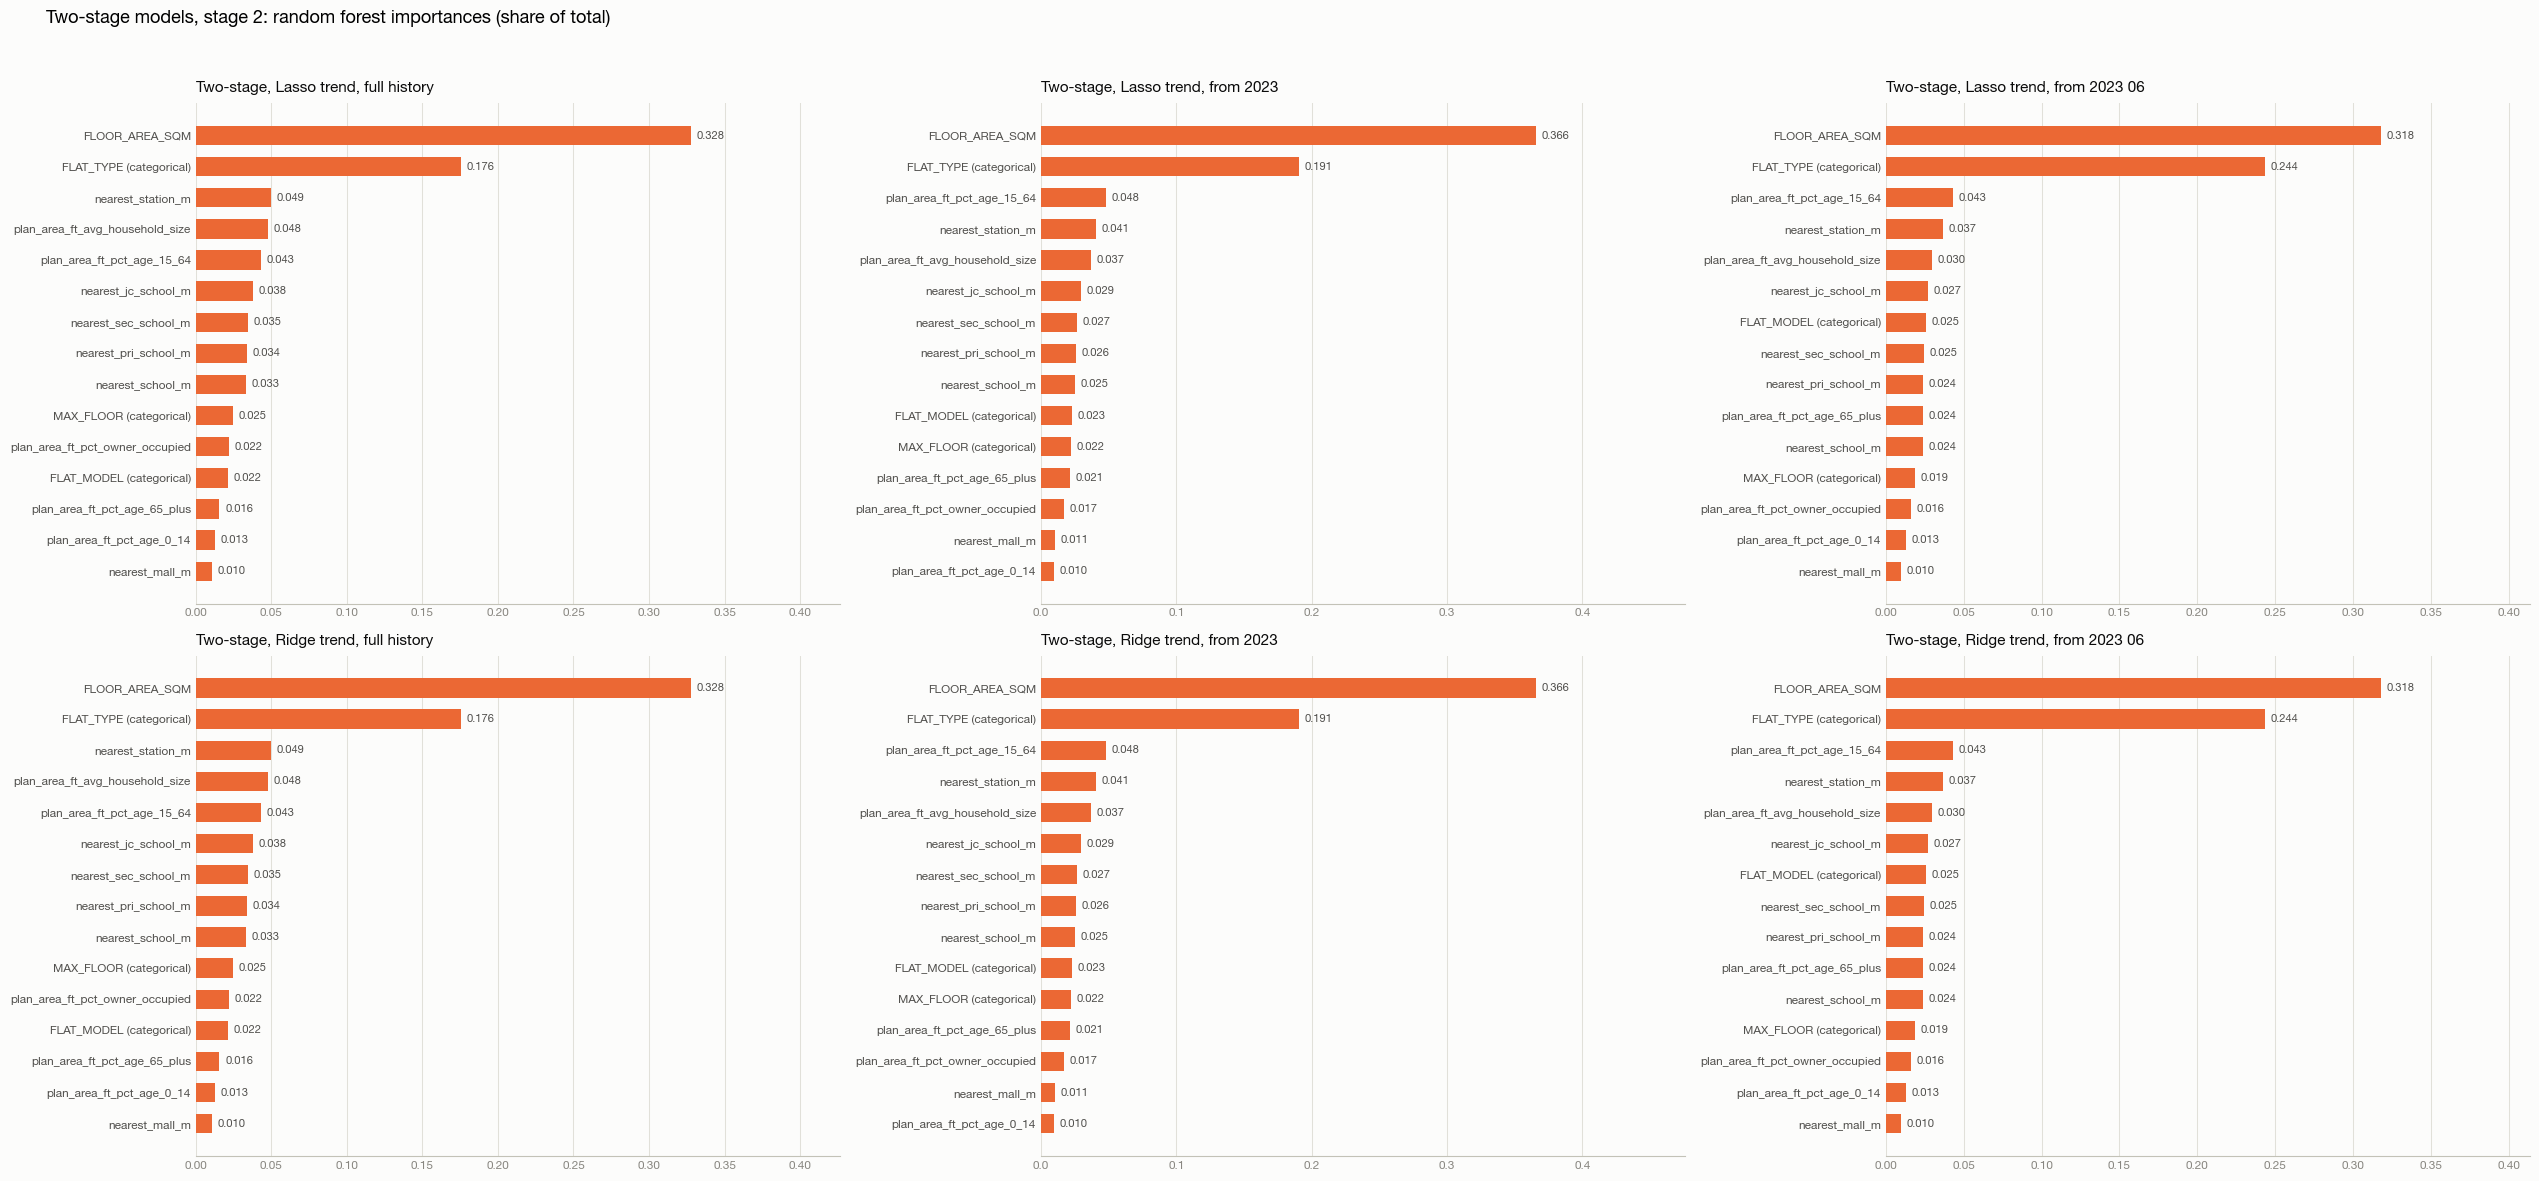

In [4]:
def static_columns(f):
    names = f['numeric'] + f['onehot']
    return names + pu.interaction_names(f['numeric'], f['selected']) if f['setup']['interactions'] else names


importances = {key: pd.Series(f['static_model'].feature_importances_, index=static_columns(f)) for key, f in fitted.items() if f['family'] in TWO_STAGE}
grouped = {key: s.groupby(group_of).sum().sort_values(ascending=False) for key, s in importances.items()}
for key in importances:
    print(f'{key}: interactions used = {fitted[key]["setup"]["interactions"]}, {len(importances[key])} columns, forest depth {fitted[key]["setup"]["static_params"]["max_depth"]}')
display(pd.DataFrame({key: g.head(12) for key, g in grouped.items()}).round(4).fillna('').rename_axis('top groups, share of importance'))

grid(TWO_STAGE, 12, 'Two-stage models, stage 2: random forest importances (share of total)', f'{OUT_DIR}/stage2_static_importances.png',
     lambda ax, key, title: plotting.bar_panel(ax, grouped[key], title, colour=plotting.HUE['orange'], top=15, fmt='{:.3f}'))

## 4. Single-stage models: Lasso and Ridge coefficients

Coefficients are on the standardised columns, so their sizes compare across features. The first table splits the total absolute weight by kind of
column; the second, by temporal feature (its own coefficient plus all of its interactions). A Ridge has no exact zeros, so its second table lists all
selected features.

In [5]:
single = {}
for key, f in fitted.items():
    if f['family'] in SINGLE_STAGE:
        single[key] = pd.Series(f['linear'].coef_, index=pu.single_stage_names(numeric, onehot, f['selected']))


def kind_of(name, selected):
    if name in selected:
        return 'temporal feature (main effect)'
    if ' x ' in name:
        return 'interaction'
    return 'static numeric' if name in numeric else 'static categorical (one-hot)'


shares = {}
for key, coefs in single.items():
    weight = coefs.abs()
    by_kind = weight.groupby([kind_of(n, fitted[key]['selected']) for n in coefs.index]).sum() / weight.sum()
    penalty = fitted[key]['setup'].get('lasso_alpha', fitted[key]['setup'].get('ridge_alpha'))
    shares[key] = {**by_kind.round(3).to_dict(), 'coefficients > 1e-6': int((weight > 1e-6).sum()), 'of': len(coefs), 'penalty': penalty}
display(pd.DataFrame(shares).rename_axis('share of total |coefficient|'))

temporal_weight = {}
for key, coefs in single.items():
    selected = fitted[key]['selected']
    owner = [n if n in selected else n.split(' x ')[1] if ' x ' in n else None for n in coefs.index]
    temporal_weight[key] = coefs.abs().groupby(owner).sum().sort_values(ascending=False)
display(pd.DataFrame({key: w.head(10) for key, w in temporal_weight.items()}).round(3).fillna('').rename_axis('temporal features: total |coefficient| (main + interactions)'))

,full_history/single_stage_lasso,full_history/single_stage_ridge,from_2023/single_stage_lasso,from_2023/single_stage_ridge,from_2023_06/single_stage_lasso,from_2023_06/single_stage_ridge
share of total |coefficient|,,,,,,
interaction,0.0950,0.461,0.018,0.209,0.021,0.249
static categorical (one-hot),0.5470,0.296,0.774,0.622,0.781,0.599
static numeric,0.1460,0.150,0.164,0.137,0.171,0.133
temporal feature (main effect),0.2120,0.093,0.044,0.032,0.027,0.019
coefficients > 1e-6,301.0000,596.000,158.000,635.000,163.000,636.000
of,597.0000,597.000,637.000,637.000,637.000,637.000
penalty,0.0001,100.000,0.001,10000.000,0.001,5000.000


,full_history/single_stage_lasso,full_history/single_stage_ridge,from_2023/single_stage_lasso,from_2023/single_stage_ridge,from_2023_06/single_stage_lasso,from_2023_06/single_stage_ridge
temporal features: total |coefficient| (main + interactions),,,,,,
MACRO_PRIVATE_RENT_RPI_YOY,0.018,0.151,,,,
MACRO_SORA_3M_PCT,0.074,0.276,0.001,0.018,,
coe_c_log_quota_premium,0.06,0.184,,,,
stk_cmon_return_volatility,,,,,0.002,0.023
stk_comfortdelgro_mom_return,,,0.0,0.014,,
stk_cytomed_therapeutics_mom_return,,,,,0.002,0.029
stk_cytomed_therapeutics_return_volatility,,,,,0.002,0.022
stk_dbs_group_return_volatility,,,,,0.0,0.03
stk_genius_group_return_volatility,,,0.004,0.026,,


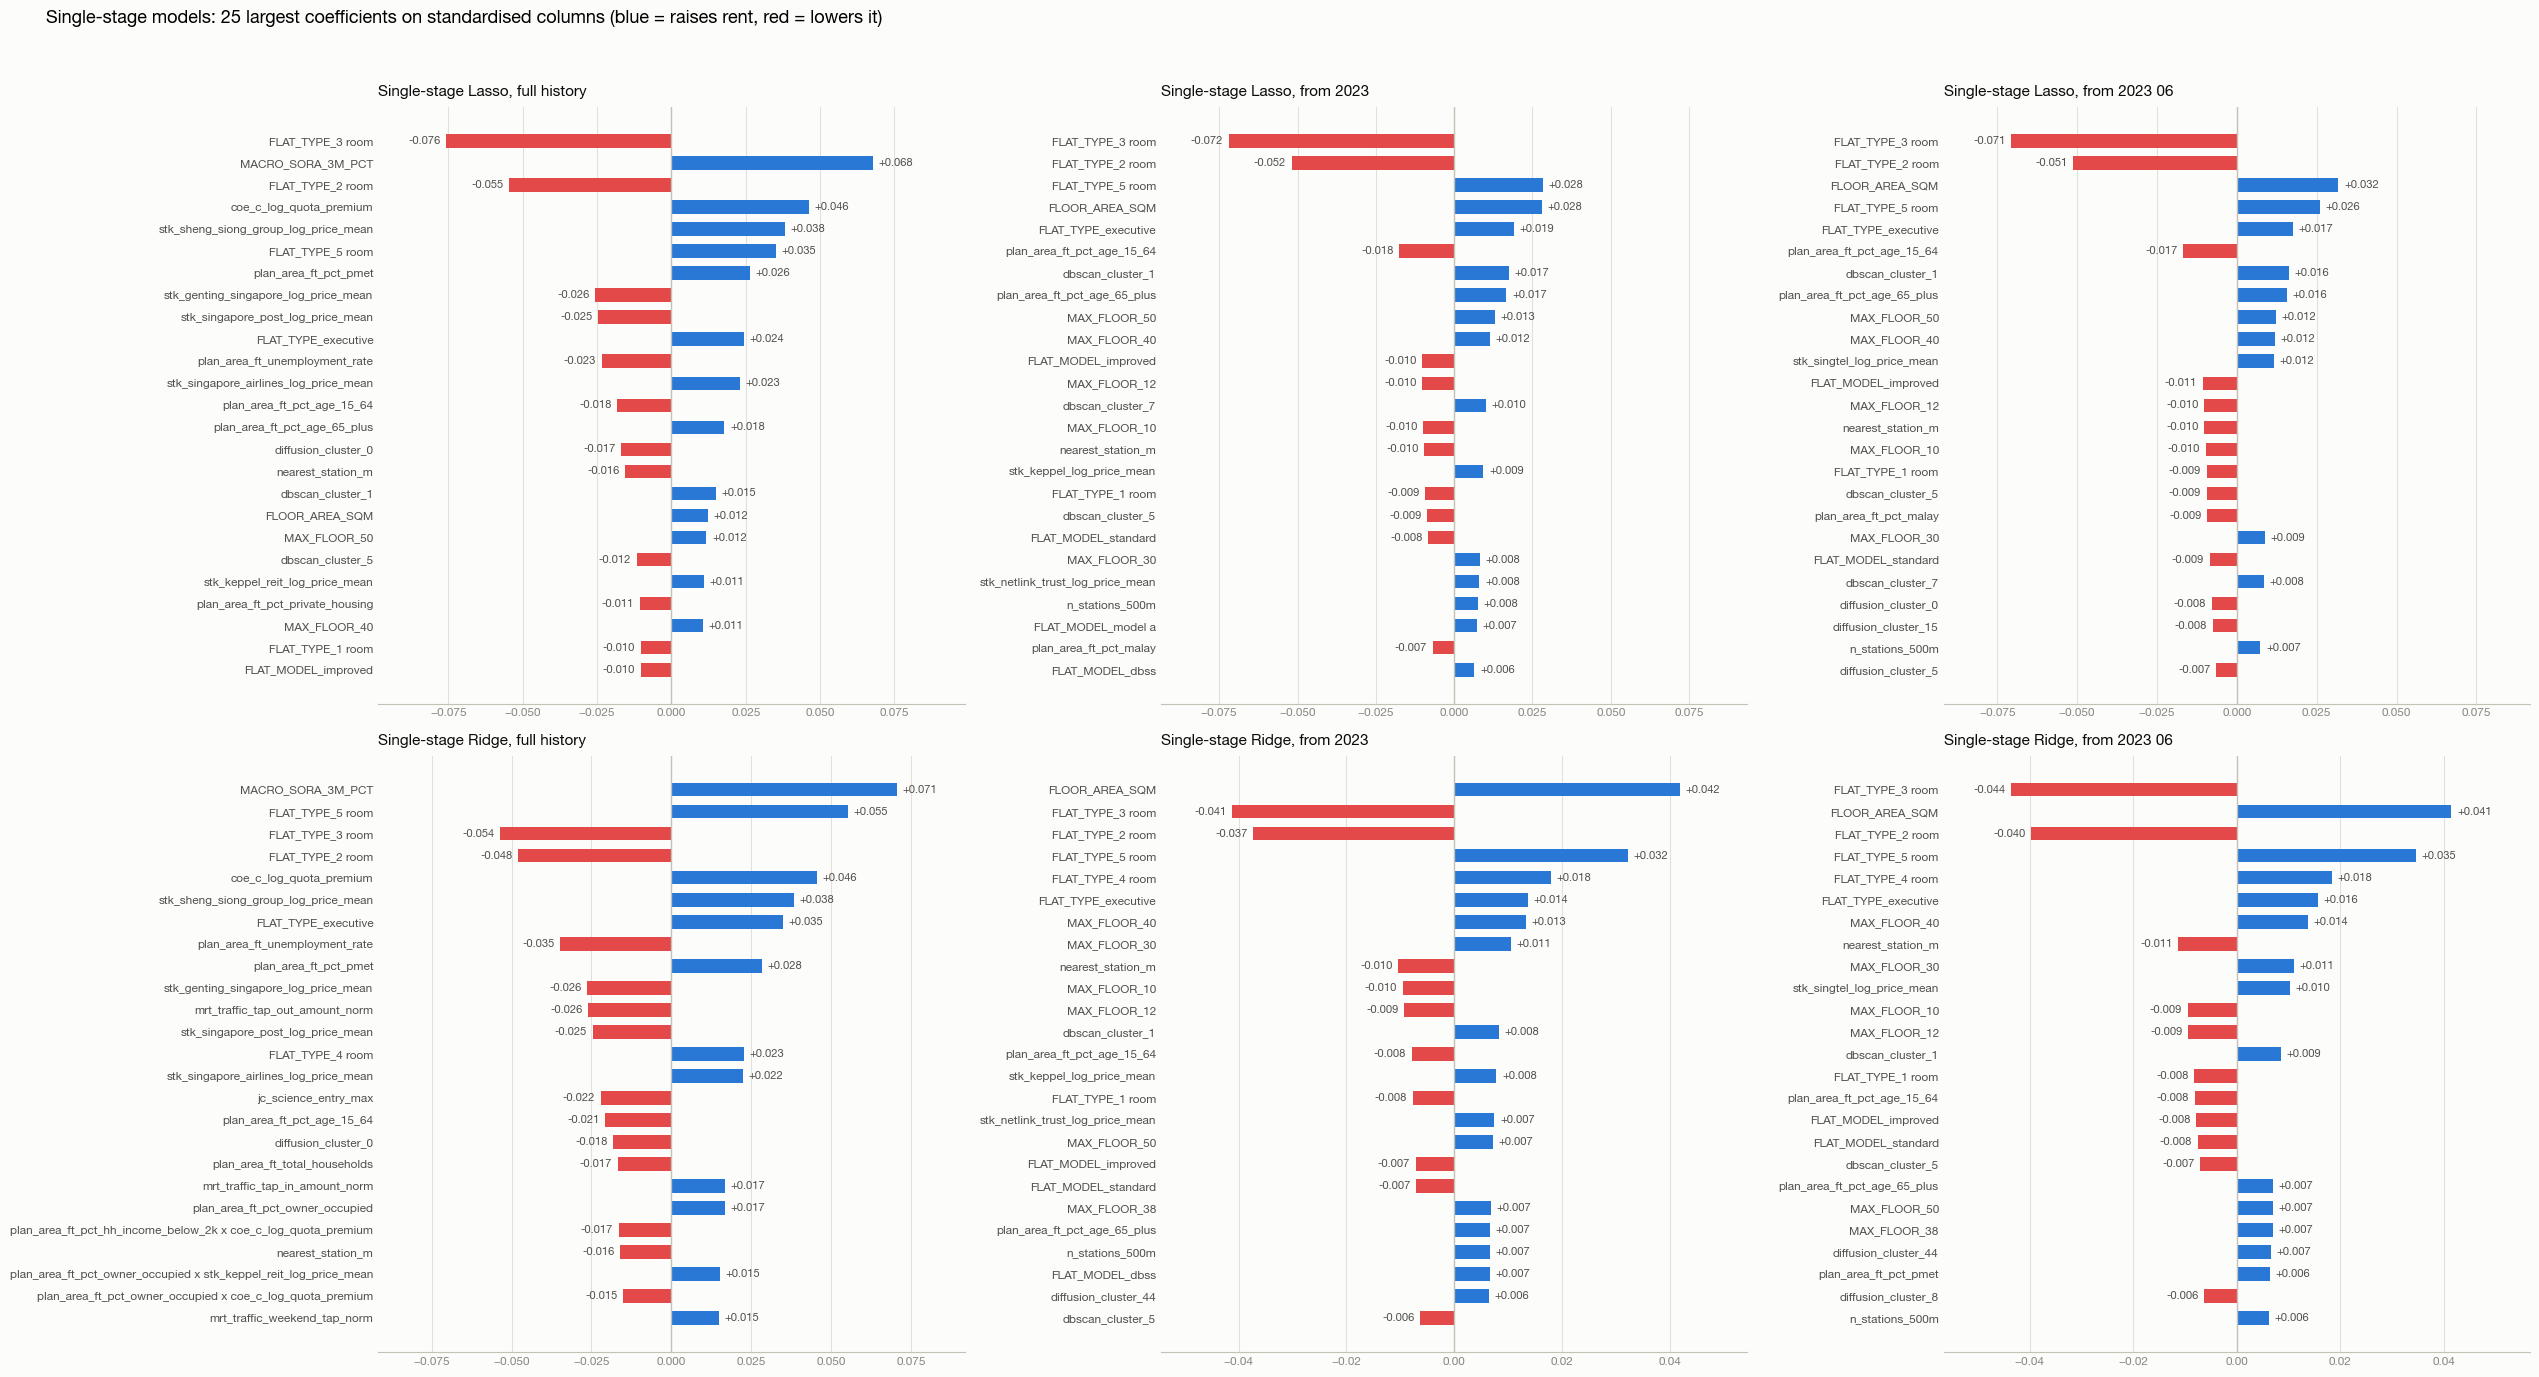

In [6]:
grid(SINGLE_STAGE, 14, 'Single-stage models: 25 largest coefficients on standardised columns (blue = raises rent, red = lowers it)',
     f'{OUT_DIR}/single_stage_coefficients.png',
     lambda ax, key, title: plotting.bar_panel(ax, single[key], title, signed=True, top=25, fmt='{:+.3f}'))